# Part 1 - Zeolite 3A and core inlet gas: results for the report

DSQ water-capture code (CPE 100). Values follow `claude/water-capture-code-spec.md` and
`claude/interface-contract.md` (21 Nov 2026):

* 1 t fresh CO2/day, full recycle: water to remove = 1.5 mol H2O per mol fresh CO2 = 25.6 kg/h
* base case X = 0.30 (CO2 conversion per pass), S = 0.60 (carbon to DME per pass), 30 bar, gas at 250 degC
* Sips working isotherm (main model, data 200-250 degC); GSTA + capillary for comparison only
* zeolite feed temperature 200-250 degC, feed loading q_in = 0 (Sips scale)

Figures (also saved as PNG files in this folder):

1. `fig1_isotherms.png` - Sips vs GSTA + capillary at 200 / 225 / 250 degC
2. `fig2_kLDF.png` - LDF rate constant vs H2O partial pressure
3. `fig3_sensitivity_X_S.png` - H2O mole fraction and gas flow into the core vs X and S
4. `fig4_min_circulation.png` - minimum zeolite circulation vs zeolite feed temperature

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from zeolite import Zeolite3A
from feed_gas import inlet_gas, gas_table, sweep_inlet_gas

zeo = Zeolite3A("parameters.csv")              # stops with OutOfRangeError outside the paper data

P_bar = 30.0                                   # core pressure (spec)
X_base = 0.30                                  # CO2 conversion per pass (spec)
S_base = 0.60                                  # carbon selectivity to DME per pass (spec)
gas = inlet_gas(X=X_base, S=S_base, P_bar=P_bar, T_C=250.0)
p_base_bar = gas["p_H2O_bar"]

T_C_list = [200, 225, 250]                     # Sips data range: 200-250 degC
colors = ["#86b6ef", "#3987e5", "#0d366b"]     # light -> dark = cold -> hot
p_values = np.arange(0.05, 4.501, 0.05)        # H2O partial pressure, bar (data range 0.05-4.5)
DPI = 200                                      # resolution of the PNG files for the report

print("Base case: X =", X_base, ", S =", S_base, ",", P_bar, "bar")
print(gas_table(gas).round(4))
print()
print("water to capture :", round(gas["water_kg_h"], 2), "kg/h")
print("gas into core    :", round(gas["F_total_mol_s"], 3), "mol/s")
print("H2O in the gas   :", round(100 * gas["y"]["H2O"], 2), "mol%")
print("pH2O at inlet    :", round(p_base_bar, 2), "bar")

Base case: X = 0.3 , S = 0.6 , 30.0 bar
         F_mol_s       y    p_bar    m_kg_h
species                                    
CO2       0.7081  0.1923   5.7692  112.1795
H2        2.3669  0.6429  19.2857   17.1771
CO        0.1214  0.0330   0.9890   12.2395
DME       0.0910  0.0247   0.7418   15.0978
H2O       0.3945  0.1071   3.2143   25.5844
total     3.6819  1.0000  30.0000  182.2783

water to capture : 25.58 kg/h
gas into core    : 3.682 mol/s
H2O in the gas   : 10.71 mol%
pH2O at inlet    : 3.21 bar


## Figure 1 - Water isotherms of zeolite 3A

Solid lines: Sips working isotherm (van Kampen et al., React. Chem. Eng. 2021).
Dashed lines: GSTA + capillary condensation (van Kampen et al., Adsorption 2021).
Black dots: check values of GSTA at 250 degC. Grey line: inlet pH2O of the base case.

    T_C  p_bar  q_sips_kgkg  q_gsta_cap_kgkg  diff_pct
0   200   0.05       0.0357           0.0367   -2.6072
1   200   0.20       0.0706           0.0744   -5.0142
2   200   1.00       0.1243           0.1177    5.6061
3   200   3.21       0.1589           0.1554    2.2791
4   200   4.50       0.1670           0.1719   -2.8902
5   225   0.05       0.0232           0.0213    8.8494
6   225   0.20       0.0493           0.0508   -2.8571
7   225   1.00       0.0983           0.0996   -1.3439
8   225   3.21       0.1372           0.1366    0.5058
9   225   4.50       0.1473           0.1493   -1.3340
10  250   0.05       0.0154           0.0124   23.4312
11  250   0.20       0.0343           0.0320    7.2126
12  250   1.00       0.0753           0.0789   -4.5789
13  250   3.21       0.1145           0.1196   -4.2436
14  250   4.50       0.1258           0.1320   -4.7244


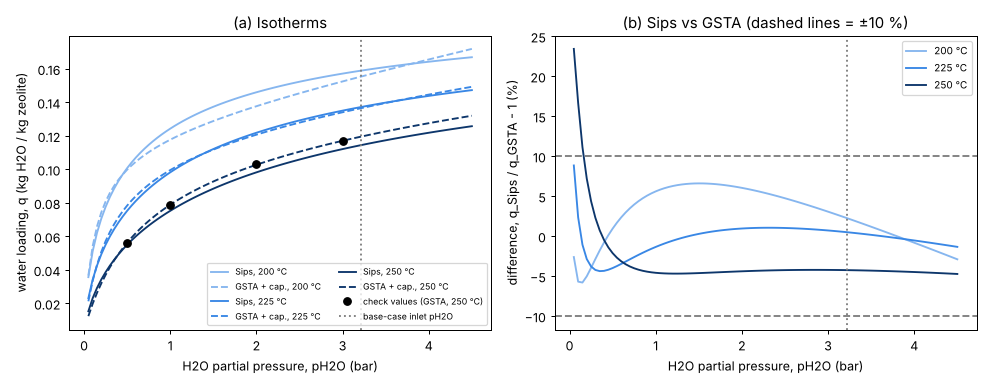

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
rows = []
for i in range(len(T_C_list)):
    T_K = T_C_list[i] + 273.15
    q_sips = []
    q_gsta = []
    difference_pct = []
    for p in p_values:
        q1 = zeo.loading(T_K, p, "sips")
        q2 = zeo.loading(T_K, p, "gsta_cap")
        q_sips.append(q1)
        q_gsta.append(q2)
        difference_pct.append(100 * (q1 / q2 - 1))
        rows.append([T_C_list[i], p, q1, q2])
    ax[0].plot(p_values, q_sips, color=colors[i], label="Sips, " + str(T_C_list[i]) + " °C")
    ax[0].plot(p_values, q_gsta, color=colors[i], linestyle="--", label="GSTA + cap., " + str(T_C_list[i]) + " °C")
    ax[1].plot(p_values, difference_pct, color=colors[i], label=str(T_C_list[i]) + " °C")

ax[0].plot([0.5, 1, 2, 3], [0.056, 0.079, 0.103, 0.117], marker="o", linestyle="",
           color="black", label="check values (GSTA, 250 °C)")
ax[0].axvline(p_base_bar, color="gray", linestyle=":", label="base-case inlet pH2O")
ax[0].set_xlabel("H2O partial pressure, pH2O (bar)")
ax[0].set_ylabel("water loading, q (kg H2O / kg zeolite)")
ax[0].set_title("(a) Isotherms")
ax[0].legend(fontsize=7, ncol=2)

ax[1].axhline(10, color="gray", linestyle="--")
ax[1].axhline(-10, color="gray", linestyle="--")
ax[1].axvline(p_base_bar, color="gray", linestyle=":")
ax[1].set_xlabel("H2O partial pressure, pH2O (bar)")
ax[1].set_ylabel("difference, q_Sips / q_GSTA - 1 (%)")
ax[1].set_title("(b) Sips vs GSTA (dashed lines = ±10 %)")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("fig1_isotherms.png", dpi=DPI)
plt.show()

isotherm_data = pd.DataFrame(rows, columns=["T_C", "p_bar", "q_sips_kgkg", "q_gsta_cap_kgkg"])
table = []
for T_C in T_C_list:
    for p in [0.05, 0.2, 1.0, p_base_bar, 4.5]:
        q1 = zeo.loading(T_C + 273.15, p, "sips")
        q2 = zeo.loading(T_C + 273.15, p, "gsta_cap")
        table.append([T_C, round(p, 2), q1, q2, 100 * (q1 / q2 - 1)])
isotherm_table = pd.DataFrame(table, columns=["T_C", "p_bar", "q_sips_kgkg", "q_gsta_cap_kgkg", "diff_pct"])
print(isotherm_table.round(4))

**Reading.** Loading rises with pH2O and falls with temperature. At the base-case inlet (3.21 bar) the
Sips working capacity is about 0.16 kg/kg at 200 degC and 0.11 kg/kg at 250 degC. The two models agree
within about 5-10 % above about 0.2 bar but drift apart at low pH2O (at 250 degC Sips is about 23 %
higher at 0.05 bar), which is where the top of the core operates, so the outlet water content is the
most model-sensitive result.

## Figure 2 - LDF rate constant

k_LDF = 15 Dc / Rc^2 with Dc = D0c exp(-Ea/RT) x Darken factor (van Kampen et al., Adsorption 2021,
Table 5; micropore term only). Grey line: base-case inlet pH2O.

    T_C  p_bar  k_LDF_1_s   tau_min
0   200   0.05    0.00120  13.88450
1   200   0.50    0.00278   5.99844
2   200   1.00    0.00327   5.10424
3   200   3.21    0.00263   6.33193
4   200   4.50    0.00221   7.52523
5   225   0.05    0.00221   7.52885
6   225   0.50    0.00368   4.52502
7   225   1.00    0.00481   3.46501
8   225   3.21    0.00558   2.98943
9   225   4.50    0.00535   3.11257
10  250   0.05    0.00420   3.97121
11  250   0.50    0.00496   3.35932
12  250   1.00    0.00632   2.63724
13  250   3.21    0.00898   1.85572
14  250   4.50    0.00945   1.76398


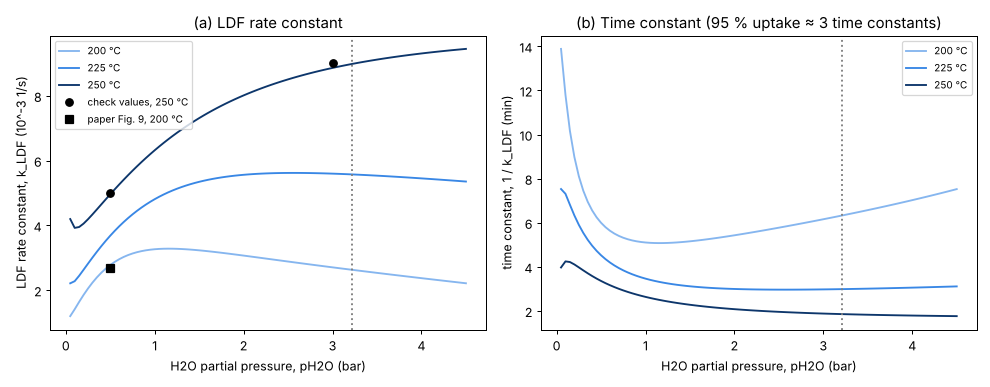

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
rows = []
for i in range(len(T_C_list)):
    T_K = T_C_list[i] + 273.15
    k_list = []
    tau_list_min = []
    for p in p_values:
        k = zeo.k_ldf(T_K, p)
        k_list.append(1000 * k)
        tau_list_min.append(1 / k / 60)
        rows.append([T_C_list[i], p, k])
    ax[0].plot(p_values, k_list, color=colors[i], label=str(T_C_list[i]) + " °C")
    ax[1].plot(p_values, tau_list_min, color=colors[i], label=str(T_C_list[i]) + " °C")

ax[0].plot([0.5, 3.0], [5.0, 9.0], marker="o", linestyle="", color="black", label="check values, 250 °C")
ax[0].plot([0.5], [2.7], marker="s", linestyle="", color="black", label="paper Fig. 9, 200 °C")
for j in range(2):
    ax[j].axvline(p_base_bar, color="gray", linestyle=":")
    ax[j].set_xlabel("H2O partial pressure, pH2O (bar)")
ax[0].set_ylabel("LDF rate constant, k_LDF (10^-3 1/s)")
ax[0].set_title("(a) LDF rate constant")
ax[1].set_ylabel("time constant, 1 / k_LDF (min)")
ax[1].set_title("(b) Time constant (95 % uptake ≈ 3 time constants)")
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig2_kLDF.png", dpi=DPI)
plt.show()

kldf_data = pd.DataFrame(rows, columns=["T_C", "p_bar", "k_LDF_1_s"])
table = []
for T_C in T_C_list:
    for p in [0.05, 0.5, 1.0, p_base_bar, 4.5]:
        k = zeo.k_ldf(T_C + 273.15, p)
        table.append([T_C, round(p, 2), k, 1 / k / 60])
kldf_table = pd.DataFrame(table, columns=["T_C", "p_bar", "k_LDF_1_s", "tau_min"])
print(kldf_table.round(5))

**Reading.** At 250 degC k_LDF is about 4-9.5 x 10^-3 1/s (time constant about 2-4 min). At 200 degC it
is about 2.2-3.3 x 10^-3 1/s above 0.5 bar (5-7.5 min) and slower near 0.05 bar (about 14 min). About
95 % of equilibrium needs three time constants, so the zeolite needs roughly 6-23 min in the core,
longest for a cold zeolite. A colder zeolite holds more water (Figure 1) but takes it up more slowly.

## Figure 3 - Sensitivity of the core inlet gas to X and S

Full recycle: the water to remove is fixed (25.6 kg/h). X and S change the gas composition per pass,
so they change the H2O mole fraction and the total gas flow into the core. Star: base case.
Dashed line in (a): y_H2O at which pH2O reaches the 4.5 bar limit of the isotherm data at 30 bar.

water to capture: 25.58 - 25.58 kg/h for every X and S

H2O in core inlet gas (mol%): rows = X, columns = S
S       0.4    0.6    0.8    1.0
X                               
0.10   3.06   3.35   3.65   3.95
0.15   4.64   5.10   5.59   6.08
0.20   6.25   6.91   7.61   8.33
0.25   7.89   8.78   9.72  10.71
0.30   9.57  10.71  11.93  13.24
0.35  11.29  12.71  14.24  15.91
0.40  13.04  14.77  16.67  18.75
0.45  14.84  16.91  19.21  21.77
0.50  16.67  19.12  21.88  25.00

Gas flow into core (mol/s): rows = X, columns = S
S        0.4     0.6     0.8    1.0
X                                  
0.10  12.887  11.774  10.820  9.994
0.15   8.503   7.728   7.063  6.487
0.20   6.312   5.705   5.185  4.734
0.25   4.997   4.491   4.058  3.682
0.30   4.120   3.682   3.306  2.981
0.35   3.494   3.104   2.769  2.480
0.40   3.024   2.670   2.367  2.104
0.45   2.659   2.333   2.054  1.812
0.50   2.367   2.063   1.803  1.578

S = 0.4 : pH2O <= 4.5 bar at 30 bar requires X <= 0.455
S = 0.6 : pH2O <= 4.5 bar

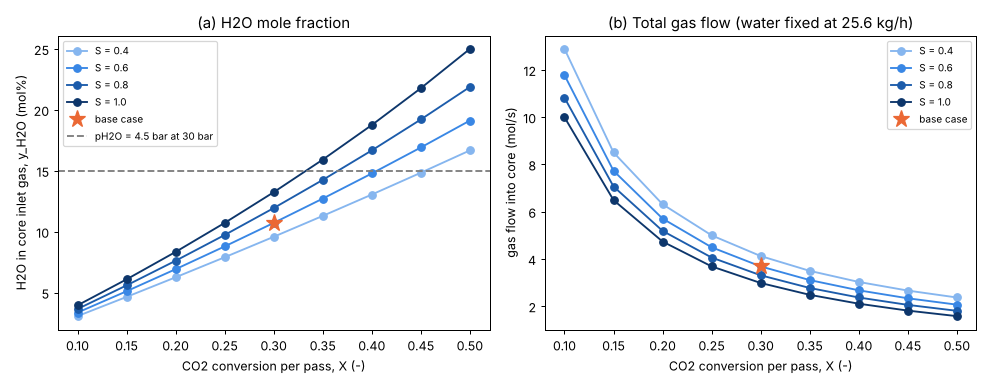

In [4]:
X_values = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
S_values = [0.4, 0.6, 0.8, 1.0]
sweep = sweep_inlet_gas(X_values, S_values, P_bar=P_bar)
S_colors = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for i in range(len(S_values)):
    one_S = sweep[abs(sweep["S"] - S_values[i]) < 1e-9]
    ax[0].plot(one_S["X"], 100 * one_S["y_H2O"], marker="o", color=S_colors[i], label="S = " + str(S_values[i]))
    ax[1].plot(one_S["X"], one_S["F_total_mol_s"], marker="o", color=S_colors[i], label="S = " + str(S_values[i]))

ax[0].plot([X_base], [100 * gas["y"]["H2O"]], marker="*", markersize=14, linestyle="", color="#eb6834", label="base case")
ax[1].plot([X_base], [gas["F_total_mol_s"]], marker="*", markersize=14, linestyle="", color="#eb6834", label="base case")
ax[0].axhline(100 * 4.5 / P_bar, color="gray", linestyle="--", label="pH2O = 4.5 bar at 30 bar")

ax[0].set_xlabel("CO2 conversion per pass, X (-)")
ax[0].set_ylabel("H2O in core inlet gas, y_H2O (mol%)")
ax[0].set_title("(a) H2O mole fraction")
ax[0].legend(fontsize=8)
ax[1].set_xlabel("CO2 conversion per pass, X (-)")
ax[1].set_ylabel("gas flow into core (mol/s)")
ax[1].set_title("(b) Total gas flow (water fixed at 25.6 kg/h)")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig3_sensitivity_X_S.png", dpi=DPI)
plt.show()

print("water to capture:", round(sweep["water_kg_h"].min(), 2), "-", round(sweep["water_kg_h"].max(), 2), "kg/h for every X and S")
print()
print("H2O in core inlet gas (mol%): rows = X, columns = S")
print((sweep.pivot(index="X", columns="S", values="y_H2O") * 100).round(2))
print()
print("Gas flow into core (mol/s): rows = X, columns = S")
print(sweep.pivot(index="X", columns="S", values="F_total_mol_s").round(3))
print()
# largest X that keeps pH2O <= 4.5 bar:  y_H2O = X (1 + S/2) / (4 - 2 S X)  ->  X = 4 y / (1 + S/2 + 2 S y)
y_max = 4.5 / P_bar
for S in S_values:
    print("S =", S, ": pH2O <= 4.5 bar at 30 bar requires X <=", round(4 * y_max / (1 + S / 2 + 2 * S * y_max), 3))

**Reading.** A higher conversion per pass means less recycle gas: at S = 0.6 the gas flow falls from
about 11.8 mol/s at X = 0.10 to about 2.1 mol/s at X = 0.50, while the H2O mole fraction rises from about
3 % to 19 %. A higher S also raises y_H2O a little. Lower gas flow helps the core (smaller pressure drop,
less risk of lifting the pellets), but a high y_H2O raises pH2O: at 30 bar and S = 0.6 the isotherm data
cover X up to about 0.41.

## Figure 4 - Minimum zeolite circulation

Equilibrium lower bound: m_zeolite,min = water / (q_eq(T_zeolite, pH2O inlet) - q_in), with the Sips
working isotherm at the base-case inlet pH2O (3.21 bar). q_in = 0 is the base case (regeneration as
good as in the paper); q_in > 0 shows incomplete regeneration.

q_in_kgkg     0.00   0.02   0.04
T_zeolite_C                     
200          161.0  184.1  215.1
205          165.3  189.8  222.9
210          169.9  196.0  231.4
215          175.0  202.8  240.9
220          180.5  210.1  251.5
225          186.4  218.2  263.1
230          192.8  227.0  276.0
235          199.7  236.6  290.3
240          207.1  247.0  306.2
245          215.0  258.4  323.8
250          223.5  270.7  343.4


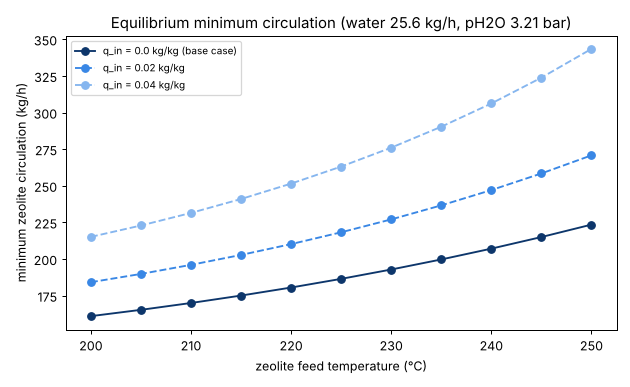

In [5]:
T_feed_C = [200, 205, 210, 215, 220, 225, 230, 235, 240, 245, 250]
q_in_list = [0.0, 0.02, 0.04]
q_in_colors = ["#0d366b", "#3987e5", "#86b6ef"]

rows = []
for T_C in T_feed_C:
    q_eq = zeo.loading(T_C + 273.15, p_base_bar, "sips")
    for q_in in q_in_list:
        rows.append([T_C, q_in, q_eq, gas["water_kg_h"] / (q_eq - q_in)])
circulation = pd.DataFrame(rows, columns=["T_zeolite_C", "q_in_kgkg", "q_eq_kgkg", "m_zeolite_min_kg_h"])

fig, ax = plt.subplots(figsize=(7, 4.3))
for i in range(len(q_in_list)):
    one = circulation[abs(circulation["q_in_kgkg"] - q_in_list[i]) < 1e-9]
    style = "-" if q_in_list[i] == 0 else "--"
    label = "q_in = " + str(q_in_list[i]) + " kg/kg" + (" (base case)" if q_in_list[i] == 0 else "")
    ax.plot(one["T_zeolite_C"], one["m_zeolite_min_kg_h"], marker="o", linestyle=style,
            color=q_in_colors[i], label=label)
ax.set_xlabel("zeolite feed temperature (°C)")
ax.set_ylabel("minimum zeolite circulation (kg/h)")
ax.set_title("Equilibrium minimum circulation (water 25.6 kg/h, pH2O 3.21 bar)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig4_min_circulation.png", dpi=DPI)
plt.show()

print(circulation.pivot(index="T_zeolite_C", columns="q_in_kgkg", values="m_zeolite_min_kg_h").round(1))

**Reading.** With q_in = 0 the minimum circulation rises from about 161 kg/h at 200 degC to about
223 kg/h at 250 degC, because a warmer zeolite holds less water. Incomplete regeneration raises it
further (q_in = 0.04 kg/kg at 250 degC: about 343 kg/h). This is a lower bound: kinetics (Figure 2)
and the temperature rise from the heat of adsorption (-60.1 kJ/mol) raise the real circulation;
Part 2's core model gives the actual value and the highest feed temperature that keeps the core at
or below 250 degC.

## Key numbers for the report

In [6]:
q_200 = zeo.loading(473.15, p_base_bar)
q_250 = zeo.loading(523.15, p_base_bar)
summary = pd.DataFrame([
    ["Fresh CO2", 1.0, "t/day"],
    ["Water to capture", gas["water_kg_h"], "kg/h"],
    ["Gas flow into core", gas["F_total_mol_s"], "mol/s"],
    ["H2O in core inlet gas", 100 * gas["y"]["H2O"], "mol%"],
    ["pH2O at core inlet", p_base_bar, "bar"],
    ["Sips capacity at 200 °C", q_200, "kg/kg"],
    ["Sips capacity at 250 °C", q_250, "kg/kg"],
    ["k_LDF at 250 °C, inlet", zeo.k_ldf(523.15, p_base_bar), "1/s"],
    ["Min. zeolite circulation, 200 °C", gas["water_kg_h"] / q_200, "kg/h"],
    ["Min. zeolite circulation, 250 °C", gas["water_kg_h"] / q_250, "kg/h"],
    ["Fresh H2 (plant)", gas["fresh_H2_kg_day"], "kg/day"],
    ["DME product (plant)", gas["DME_kg_day"], "kg/day"],
], columns=["quantity", "value", "unit"])
print(summary.round(4))

                            quantity     value    unit
0                          Fresh CO2    1.0000   t/day
1                   Water to capture   25.5844    kg/h
2                 Gas flow into core    3.6819   mol/s
3              H2O in core inlet gas   10.7143    mol%
4                 pH2O at core inlet    3.2143     bar
5            Sips capacity at 200 °C    0.1589   kg/kg
6            Sips capacity at 250 °C    0.1145   kg/kg
7             k_LDF at 250 °C, inlet    0.0090     1/s
8   Min. zeolite circulation, 200 °C  160.9620    kg/h
9   Min. zeolite circulation, 250 °C  223.4515    kg/h
10                  Fresh H2 (plant)  137.4167  kg/day
11               DME product (plant)  523.3915  kg/day


## Export tables to Excel

In [7]:
isotherm_table.to_excel("part1_isotherms.xlsx", index=False)
kldf_table.to_excel("part1_kLDF.xlsx", index=False)
sweep.to_excel("part1_sweep_X_S.xlsx", index=False)
circulation.to_excel("part1_min_circulation.xlsx", index=False)
summary.to_excel("part1_key_numbers.xlsx", index=False)
print("written: part1_isotherms.xlsx, part1_kLDF.xlsx, part1_sweep_X_S.xlsx,")
print("         part1_min_circulation.xlsx, part1_key_numbers.xlsx")

written: part1_isotherms.xlsx, part1_kLDF.xlsx, part1_sweep_X_S.xlsx,
         part1_min_circulation.xlsx, part1_key_numbers.xlsx
